In [84]:
import numpy as np
import pandas as pd
import scipy

from IPython.display import clear_output

import re
from pathlib import Path
import requests
import random
import time
import scipy
from bs4 import BeautifulSoup
import gc
import json
import glob

from tqdm import tqdm

In [85]:
combo_df = pd.read_csv('../data/260711_combined_journal_select_properties.csv')

In [86]:
di = {'international_citation_index':'ici', 
      'international_impact_factor_services':'iifs'}
combo_df['service'] = combo_df['service'].map(di).fillna(combo_df['service'])

In [87]:
pred_services = combo_df['service'].unique()

In [88]:
indexing_df = pd.read_csv('../data/261028_combined_journal_level_datasets.csv')
indexing_df = indexing_df[~((indexing_df['service'] == 'abdc') & (indexing_df['edition'] != 2025))]
indexing_df = indexing_df[indexing_df['service'].isin(['scopus', 'doaj', 'wos', 'kijl', 'abdc', 'rw_hjc', 'cas_ewl', 'jufo'])].copy()
indexing_df['service'] = indexing_df['service'] + '_' + indexing_df['indexing_status']
indexing_df = indexing_df.drop_duplicates(subset=['service', 'journal_title', 'p_issn', 'e_issn'])
indexing_df['uid'] = range(len(indexing_df))

C:\Users\richa\AppData\Local\Temp\ipykernel_32620\1399865422.py:1: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  indexing_df = pd.read_csv('../data/261028_combined_journal_level_datasets.csv')


In [89]:
leg_services = indexing_df['service'].unique()
print(leg_services)

['abdc_indexed' 'cas_ewl_indexed' 'doaj_indexed' 'doaj_deindexed'
 'jufo_indexed' 'jufo_deindexed' 'kijl_indexed' 'kijl_deindexed'
 'rw_hjc_indexed' 'scopus_indexed' 'scopus_deindexed' 'wos_indexed'
 'wos_deindexed']


In [90]:
collect = []
f = indexing_df[['uid', 'service', 'p_issn']].rename(columns={'p_issn':'value'})
f['key'] = 'issn'
f = f.dropna(subset=['value'])
collect.append(f)

f = indexing_df[['uid', 'service', 'e_issn']].rename(columns={'e_issn':'value'})
f['key'] = 'issn'
f = f.dropna(subset=['value'])
collect.append(f)

issn_slice = pd.concat(collect)

issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
collect_issns = []
for uid, issn_str, service in tqdm(zip(issn_slice['uid'].values, 
                                       issn_slice['value'].values, 
                                       issn_slice['service'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn], 'service':[service]}))
issn_df = pd.concat(collect_issns)
collect = []
collect.append(issn_df)

f = indexing_df[['uid', 'service', 'journal_title']].rename(columns={'journal_title':'value'})
f['key'] = 'title'
f = f.dropna(subset=['value'])
collect.append(f)

indexing_df = pd.concat(collect)

221771it [00:40, 5508.87it/s]


In [91]:
combo_df = pd.concat([combo_df, indexing_df])

In [92]:
combo_df[combo_df['key'] == 'issn'].groupby('service')['uid'].nunique()

service
abdc_indexed         2646
cas_ewl_indexed        29
cosmos               6522
doaj_deindexed       4378
doaj_indexed        23545
drji                 8876
esji                 8542
ici                   126
ifj                   609
ifsij                 857
iifs                 2315
jufo_deindexed       7446
jufo_indexed        26155
kijl_deindexed        955
kijl_indexed         5903
rw_hjc_indexed        415
scopus_deindexed     1161
scopus_indexed      33248
sjif                 9214
wos_deindexed         238
wos_indexed         23004
Name: uid, dtype: int64

In [93]:
combo_df[(combo_df['key'] == 'title') & (combo_df['value'].str.contains('British Medical Journal'))]

,service,uid,key,value
119849,sjif,22119,title,British Medical Journal
221206,sjif,22119,title,British Medical Journal
90350,scopus_indexed,76656,title,British Medical Journal


# How many unique journals in each index and how many share ISSNs with one another?

In [94]:
combo_df['service_uid'] = combo_df['service'] + '_' + combo_df['uid'].astype(str)
issn_df = combo_df[combo_df['key'] == 'issn'].copy()
issn_df['value'] = issn_df['value'].str.upper()

bad_issns = ['0000-0000']
issn_df = issn_df[~issn_df['value'].isin(bad_issns)].copy()

In [95]:
def format_issn(issn_str):
    return issn_str[0:4] + '-' + issn_str[4:]
issn_df.loc[issn_df['value'].apply(len) == 8, 'value'] = issn_df.loc[issn_df['value'].apply(len) == 8, 'value'].apply(format_issn)

In [96]:
def modulo_11_check(issn_str):
    try:
        this_sum = 8*int(issn_str[0]) + 7*int(issn_str[1]) + 6*int(issn_str[2]) + 5*int(issn_str[3]) +\
            4*int(issn_str[5]) + 3*int(issn_str[6]) + 2*int(issn_str[7])
        modulo = this_sum % 11
        if modulo == 0:
            check_digit = '0'
        else:
            check_digit = str(11 - modulo)
            if check_digit == '10':
                check_digit = 'X'
        return issn_str[-1] == check_digit
    except:
        print(issn_str)

In [97]:
modulo_11_check('0378-5955')

True

In [98]:
modulo_11_check('2582-5206')

False

In [99]:
issn_df['modulo_11_check'] = issn_df['value'].apply(modulo_11_check)

# How many entries fail a modulus 11 check?

In [104]:
issn_df[issn_df['modulo_11_check'] == False].groupby('service')['service_uid'].nunique().sort_values(ascending=False)

service
esji                179
drji                137
cosmos               80
iifs                 22
ifj                  20
sjif                 11
abdc_indexed          8
ifsij                 7
rw_hjc_indexed        5
kijl_indexed          3
scopus_deindexed      3
wos_indexed           3
jufo_deindexed        2
doaj_deindexed        1
ici                   1
wos_deindexed         1
Name: service_uid, dtype: int64

In [105]:
issn_df = issn_df[issn_df['modulo_11_check']].copy()

In [106]:
%%time
# merge issns that map into the same identity

merge_df = pd.merge(issn_df[['service_uid', 'value']], issn_df[['service_uid', 'value']], on='service_uid')
#merge_df = merge_df[merge_df['value_x'] != merge_df['value_y']]
merge_df.columns = ['service_uid', 'source', 'target']

CPU times: total: 297 ms
Wall time: 300 ms


In [107]:
import networkx as nx

In [108]:
G = nx.from_pandas_edgelist(merge_df[['source', 'target']])

In [109]:
%%time
cc = nx.connected_components(G)

collect = []
global_uid = 0
for comp in tqdm(cc):
    for issn in comp:
        collect.append(pd.DataFrame({'global_uid':[global_uid], 'issn':[issn]}))
    global_uid += 1

global_uid_df = pd.concat(collect)

78486it [00:17, 4496.16it/s]


CPU times: total: 25.6 s
Wall time: 25.7 s


In [110]:
issn_df = pd.merge(issn_df, global_uid_df, left_on='value', right_on='issn')

In [111]:
# the number of times the same journal is listed multiple times in each service

issn_df.groupby(['global_uid', 'service'])['service_uid'].nunique().reset_index().groupby('service')['service_uid'].value_counts()

service           service_uid
abdc_indexed      1               2644
cas_ewl_indexed   1                 29
cosmos            1               5287
                  2                473
                  3                 68
                  4                  8
doaj_deindexed    1               4295
                  2                 41
doaj_indexed      1              23521
                  2                 12
drji              1               8676
                  2                 31
esji              1               8420
                  2                 14
                  3                  1
ici               1                123
                  2                  1
ifj               1                507
                  2                 28
                  3                  6
                  4                  1
                  7                  1
ifsij             1                763
                  2                 40
                  3               

# How many journals are indexed by one or more predatory services?

In [115]:
issn_df[issn_df['service'].isin(pred_services)]['global_uid'].nunique()

21254

In [150]:
issn_df[issn_df['service'].isin(pred_services)].groupby('global_uid')['service'].nunique().value_counts()

1    12524
2     4885
3     2381
4     1056
5      306
6       95
7        6
8        1
Name: service, dtype: int64

# How many journal identities recovered in total?

In [117]:
issn_df['global_uid'].nunique()

78486

In [118]:
n_pred_services = issn_df[issn_df['service'].isin(pred_services)].groupby('global_uid')['service'].nunique()

In [119]:
# create neat spreadsheet

global_uid_to_issn = issn_df.groupby('global_uid')['issn'].apply(set).apply(lambda x: ', '.join(x))

service_uid_to_title = combo_df[(combo_df['key'] == 'title')][['service_uid', 'value']].rename(columns={'value':'title'})
spread_df = pd.merge(issn_df, service_uid_to_title, on='service_uid', how='left')

service_uid_to_url = combo_df[(combo_df['key'] == 'url')][['service_uid', 'value']].rename(columns={'value':'url'})
spread_df = pd.merge(spread_df, service_uid_to_url, on='service_uid', how='left')

one_row_per_journal_df = pd.DataFrame(index = spread_df['global_uid'].unique())
for col in ['title', 'url', 'issn', 'service']:
    one_row_per_journal_df[col + 's'] = \
    spread_df.groupby('global_uid')[col].apply(set).apply(lambda x: ', '.join([str(a) for a in x]))
    
one_row_per_journal_df['n_pred_services'] = n_pred_services
one_row_per_journal_df['n_pred_services'] = one_row_per_journal_df['n_pred_services'].fillna(0)

one_row_per_journal_df = one_row_per_journal_df.sort_values('n_pred_services', ascending=False)

one_row_per_journal_df = one_row_per_journal_df.reset_index().rename(columns={'index':'global_uid'})

In [120]:
one_row_per_journal_df.to_csv('../data/261028_one_row_per_journal.csv', encoding='utf-8', index=False)

In [121]:
issn_df[issn_df['value'] == '1307-234X']

,service,uid,key,value,service_uid,modulo_11_check,global_uid,issn
11653,sjif,18857,issn,1307-234X,sjif_18857,True,1857,1307-234X
11654,esji,7306.0,issn,1307-234X,esji_7306.0,True,1857,1307-234X
11655,cosmos,3243,issn,1307-234X,cosmos_3243,True,1857,1307-234X
11656,cosmos,8084,issn,1307-234X,cosmos_8084,True,1857,1307-234X
11657,cosmos,8084,issn,1307-234X,cosmos_8084,True,1857,1307-234X
11658,sjif,18857,issn,1307-234X,sjif_18857,True,1857,1307-234X
11659,esji,7306.0,issn,1307-234X,esji_7306.0,True,1857,1307-234X
11660,cosmos,3243,issn,1307-234X,cosmos_3243,True,1857,1307-234X
11661,cosmos,8084,issn,1307-234X,cosmos_8084,True,1857,1307-234X
11662,cosmos,8084,issn,1307-234X,cosmos_8084,True,1857,1307-234X


In [122]:
spread_df['wow'] = True
tab = spread_df.drop_duplicates(['global_uid', 'service']).pivot(index=['global_uid'], 
                                                           columns=['service'], 
                                                           values='wow').fillna(False).reset_index()

In [123]:
pd.merge(one_row_per_journal_df, tab, on='global_uid').to_csv('../data/261028_one_row_per_journal_with_bool_cols.csv', 
                                                              index=False)

# How many journals in each index?

In [124]:
issn_df.groupby('service')['global_uid'].nunique()

service
abdc_indexed         2644
cas_ewl_indexed        29
cosmos               5836
doaj_deindexed       4336
doaj_indexed        23533
drji                 8707
esji                 8435
ici                   124
ifj                   543
ifsij                 805
iifs                 2171
jufo_deindexed       7444
jufo_indexed        26151
kijl_deindexed        953
kijl_indexed         5901
rw_hjc_indexed        395
scopus_deindexed     1156
scopus_indexed      33244
sjif                 9190
wos_deindexed         238
wos_indexed         23000
Name: global_uid, dtype: int64

In [204]:
issn_df['global_uid'].nunique()

78486

In [129]:
set_dict = issn_df.groupby('service')['global_uid'].apply(set)

# How many of these journals are indexed by Scopus?

In [148]:
pred_and_scopus = set_dict.get('scopus_indexed') & set(n_pred_services.index)
print(len(pred_and_scopus))

1293


# How many of these journals are indexed by DOAJ?

In [151]:
pred_and_scopus = set_dict.get('doaj_indexed') & set(n_pred_services.index)
print(len(pred_and_scopus))

2915


# How many of these journals are indexed by WoS and have JIFs?

In [152]:
pred_and_wos = set_dict.get('wos_indexed') & set(n_pred_services.index)
print(len(pred_and_wos))

797


In [153]:
# spot check
np.random.seed(10)
one_row_per_journal_df[one_row_per_journal_df['global_uid'].isin(pred_and_wos)].sample(10)

,global_uid,titles,urls,issns,services,n_pred_services
1904,3881,"Information Technologies and Learning Tools, I...","nan, http://journal.iitta.gov.ua/, http://jour...",2076-8184,"jufo_deindexed, wos_indexed, doaj_indexed, esj...",3.0
15302,4321,"Iranian journal of parasitology, Iranian Journ...","nan, http://journals.tums.ac.ir/description.as...","2008-238X, 1735-7020","jufo_deindexed, wos_indexed, doaj_indexed, sco...",1.0
13000,17753,"Jundishapur Journal of Microbiology, Jundishap...","nan, http://jjmicrobiol.com/","2008-3645, 2008-4161","wos_indexed, drji, scopus_indexed, kijl_indexe...",1.0
12965,17684,"Actualidades en Psicología, Actualidades en Ps...","nan, http://www.revistas.ucr.ac.cr/index.php/a...","0258-6444, 2215-3535","wos_indexed, drji, doaj_indexed, scopus_indexed",1.0
17952,2793,"REVISTA BIO CIENCIAS, Revista Bio Ciencias","nan, http://revistabiociencias.uan.mx",2007-3380,"wos_indexed, doaj_indexed, sjif",1.0
9122,21081,Advances in Electrical and Electronic Engineer...,nan,"1804-3119, 1336-1376","scopus_indexed, doaj_indexed, wos_indexed, ifj",1.0
8442,13330,"Papireto, PAPIRETO","nan, https://papireto.accademiadipalermo.it/",2974-668X,"wos_indexed, drji, doaj_indexed, esji",2.0
6061,1222,"MOLECULAR BIOLOGY RESEARCH COMMUNICATIONS, Mol...","nan, http://mbrc.shirazu.ac.ir","2345-2005, 2322-181X","scopus_indexed, drji, wos_indexed, sjif",2.0
17418,3860,INTERNATIONAL JOURNAL OF WOMENS HEALTH AND REP...,"nan, http://www.ijwhr.net",2330-4456,"wos_indexed, doaj_deindexed, scopus_indexed, sjif",1.0
13593,17114,MEDITERRANEAN AGRICULTURAL SCIENCES,"nan, http://www.dergipark.gov.tr/mediterranean",2528-9675,"wos_indexed, drji",1.0


# How many in RW HJC?

In [310]:
pred_and_wos = set_dict.get('rw_hjc_indexed') & set(n_pred_services.index)
print(len(pred_and_wos))

39


In [155]:
count_df = pd.merge(issn_df, n_pred_services.reset_index().rename(columns={'service':'n_pred_services'}), on='global_uid')\
.groupby(['service', 'n_pred_services']).nunique()['global_uid'].loc[leg_services].reset_index()\
.pivot(index='n_pred_services', columns='service', values='global_uid').fillna(0)\
[['abdc_indexed', 'doaj_indexed', 'jufo_indexed', 'kijl_indexed', 'scopus_indexed', 'wos_indexed']]

count_df.astype(float)
for col in count_df.columns:
    count_df[col] = count_df[col]\
 .apply(lambda x: '{:,.0f}'.format(x))

In [156]:
count_df

service,abdc_indexed,doaj_indexed,jufo_indexed,kijl_indexed,scopus_indexed,wos_indexed
n_pred_services,,,,,,
1,58,"1,929",367,51,909,603
2,5,662,69,3,227,133
3,5,230,15,1,99,42
4,3,75,8,0,37,11
5,1,14,1,0,17,7
6,0,5,1,0,4,1
7,0,0,0,0,0,0


In [157]:
pd.merge(issn_df[issn_df['service'].isin(['wos_indexed'])], 
         n_pred_services.reset_index().rename(columns={'service':'n_pred_services'}), on='global_uid')\
.sort_values('n_pred_services')['n_pred_services'].value_counts()

1    1169
2     256
3      81
4      22
5      13
6       2
Name: n_pred_services, dtype: int64

In [158]:
count_df.to_csv('../data/261028_count_number_of_pred_services_table.csv')

In [159]:
count_df

service,abdc_indexed,doaj_indexed,jufo_indexed,kijl_indexed,scopus_indexed,wos_indexed
n_pred_services,,,,,,
1,58,"1,929",367,51,909,603
2,5,662,69,3,227,133
3,5,230,15,1,99,42
4,3,75,8,0,37,11
5,1,14,1,0,17,7
6,0,5,1,0,4,1
7,0,0,0,0,0,0


In [160]:
n_pred_services.loc[(set_dict.get('doaj_indexed') | set_dict.get('scopus_indexed') | \
                    set_dict.get('wos_indexed') | set_dict.get('abdc_indexed') | \
                    set_dict.get('jufo_indexed') | set_dict.get('kijl_indexed')) \
                    & set(n_pred_services.index)].to_csv('../data/261028_n_pred_services_indexed_journals.csv')

C:\Users\richa\AppData\Local\Temp\ipykernel_32620\731305148.py:1: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  n_pred_services.loc[(set_dict.get('doaj_indexed') | set_dict.get('scopus_indexed') | \


# How many journals in legitimate indices that are in 4 or more predatory indices?

In [311]:
issn_df[issn_df['service'].isin(leg_services) & \
        issn_df['global_uid'].isin(n_pred_services[n_pred_services >= 4].index)].groupby('service')['global_uid'].nunique()

service
abdc_indexed         4
doaj_deindexed      90
doaj_indexed        94
jufo_deindexed      61
jufo_indexed        10
kijl_deindexed      11
rw_hjc_indexed       3
scopus_deindexed    33
scopus_indexed      58
wos_deindexed        5
wos_indexed         19
Name: global_uid, dtype: int64

In [162]:
n_pred_services.to_csv('../data/261028_n_pred_services.csv')

In [163]:
net_df = []
for service_0 in set_dict.keys():
    for service_1 in set_dict.keys():
        set_0 = set_dict.get(service_0)
        set_1 = set_dict.get(service_1)
        set_combo = set_0 & set_1
        net_df.append(pd.DataFrame({'source':[service_0], 'target':[service_1], 'weight':[len(set_combo)]}))
        
net_df = pd.concat(net_df)

In [164]:
pred_services = sorted(pred_services)
services = list(pred_services) + list(leg_services)

# How much more likely are journals in predatory indices to be de-indexed in legitimate indices?

In [178]:
leg_services

array(['abdc_indexed', 'cas_ewl_indexed', 'doaj_indexed',
       'doaj_deindexed', 'jufo_indexed', 'jufo_deindexed', 'kijl_indexed',
       'kijl_deindexed', 'rw_hjc_indexed', 'scopus_indexed',
       'scopus_deindexed', 'wos_indexed', 'wos_deindexed'], dtype=object)

In [212]:
from scipy.stats import chi2_contingency

In [305]:
def chi_squared_deindexing(name_of_index='scopus'):
    at_least_one_pred = set(n_pred_services.index)
    legit_index = set_dict.get(name_of_index + '_indexed')
    legit_deindexed = set_dict.get(name_of_index + '_deindexed')
    legit_index = legit_index - legit_deindexed # remove those that appear in both
    legit_deindexed = legit_deindexed - legit_index # remove those that appear in both
    legit_index_zero_pred = legit_index - at_least_one_pred
    legit_deindexed_zero_pred = legit_deindexed - at_least_one_pred
    legit_index_at_least_one_pred = legit_index & at_least_one_pred
    legit_deindex_at_least_one_pred = legit_deindexed & at_least_one_pred

    contingency = np.array([[len(legit_index_zero_pred), len(legit_deindexed_zero_pred)],
    [len(legit_index_at_least_one_pred), len(legit_deindex_at_least_one_pred)]])

    print(contingency)

    likelihoods = contingency[:,1]/np.sum(contingency, axis=1)
    lr = likelihoods[1]/likelihoods[0]
    res = chi2_contingency(contingency)
    pval = res.pvalue
    stat = res.statistic
    print('$\chi^2(1, N = ' + str(np.sum(contingency)) + ') = $' + str(stat) + ', p = ' + str(pval))
    print(lr)
    print(res)
    return ['{:,.0f}'.format(len(legit_index_zero_pred)), '{:,.0f}'.format(len(legit_deindexed_zero_pred)), 
            '{:,.0f}'.format(len(legit_index_at_least_one_pred)), '{:,.0f}'.format(len(legit_deindex_at_least_one_pred)),
            '{:.2f}'.format(lr), '{:.2e}'.format(pval)]

In [306]:
index_col = ['In zero predatory, indexed by legitimate', 
             'In zero predatory, de-indexed by legitimate', 
             'In 1+ predatory, indexed by legitimate', 
             'In 1+ predatory, de-indexed by legitimate', 
             'likelihood_ratio', 
             'p']
res_df = pd.DataFrame(index=index_col)
for name_of_index in ['doaj', 'jufo', 'kijl', 'scopus', 'wos']:
    col = chi_squared_deindexing(name_of_index)
    res_df[name_of_index] = col

[[20057  3230]
 [ 2729  1106]]
$\chi^2(1, N = 27122) = $548.227637932804, p = 3.058806534035482e-121
2.0792216064357536
Chi2ContingencyResult(statistic=548.227637932804, pvalue=3.058806534035482e-121, dof=1, expected_freq=array([[19564.10227859,  3722.89772141],
       [ 3221.89772141,   613.10227859]]))
[[25687  6697]
 [  461   747]]
$\chi^2(1, N = 33592) = $1141.2632399234103, p = 3.5538876136902486e-250
2.9902249400987095
Chi2ContingencyResult(statistic=1141.2632399234103, pvalue=3.5538876136902486e-250, dof=1, expected_freq=array([[25207.6932603,  7176.3067397],
       [  940.3067397,   267.6932603]]))
[[5846  845]
 [  55  108]]
$\chi^2(1, N = 6854) = $377.82927178513256, p = 3.694591304242873e-84
5.246509601771518
Chi2ContingencyResult(statistic=377.82927178513256, pvalue=3.694591304242873e-84, dof=1, expected_freq=array([[5760.66399183,  930.33600817],
       [ 140.33600817,   22.66399183]]))
[[31951   875]
 [ 1293   281]]
$\chi^2(1, N = 34400) = $1062.0623287094359, p = 5.815039

In [300]:
res_df.to_csv('../data/261111_deindexing_likelihood_ratios.csv')

# Nice matrix

In [169]:
share_matrix = net_df.pivot(columns='source', index='target', values='weight')
share_matrix = share_matrix.loc[services][services]

In [170]:
import matplotlib.pyplot as plt
import seaborn as sns

In [171]:
services = pred_services + ['abdc_indexed',
 'doaj_indexed', 
'jufo_indexed',  
 'kijl_indexed', 
 'scopus_indexed',
 'wos_indexed',
'doaj_deindexed',
'jufo_deindexed', 
'kijl_deindexed',
'scopus_deindexed',
'wos_deindexed', 
'rw_hjc_indexed',
'cas_ewl_indexed']

services_labels = ['CIF',
 'DRJI',
 'ESJI',
 'ICI',
 'IFJ',
 'IFSIJ',
 'IIFS',
 'SJIF',
 'ABDC JQL',
 'DOAJ',
 'JUFO (levels 1-3)',
 'KI-JL (levels 1-3)',
 'Scopus',
 'WoS',
'DOAJ de-indexed','JUFO (level 0)','KI-JL (level 0)','Scopus de-indexed', 'WoS de-indexed',
 'RW HJC',
 'CAS EWL'] 

<Figure size 432x288 with 0 Axes>

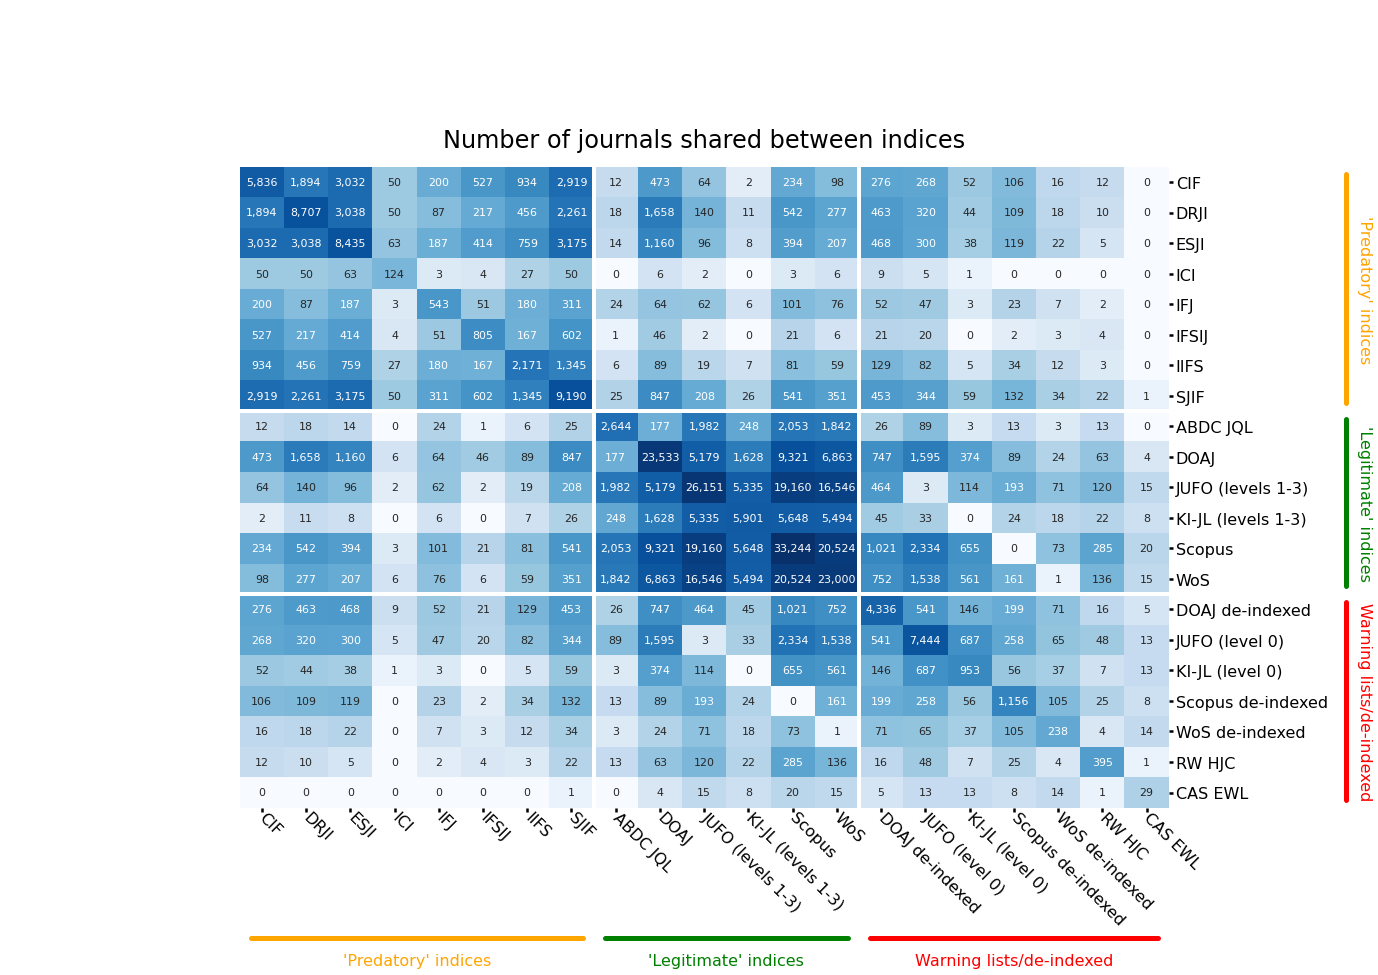

In [175]:
fig = plt.figure()
mask = ~np.ones_like(share_matrix, dtype=bool)

g = sns.clustermap(np.log10(share_matrix.loc[services][services]+1), 
            annot=share_matrix.loc[services][services], fmt=',.0f', mask=mask, annot_kws={'fontsize':11},
                   col_cluster=False, row_cluster=False, figsize=(18,13), cmap='Blues', cbar=False)

g.ax_heatmap.set_xticklabels(services_labels)
g.ax_heatmap.set_yticklabels(services_labels)
g.ax_heatmap.tick_params(bottom=True, labelsize=16, axis='x', labelrotation=-45)
g.ax_heatmap.tick_params(bottom=True, labelsize=16, axis='y', labelrotation=0)
g.ax_heatmap.tick_params(width=1.25)
g.ax_heatmap.set_xticklabels(labels=g.ax_heatmap.xaxis.get_ticklabels(), 
                             rotation=-45, ha='left', va='center', rotation_mode='anchor')
g.ax_heatmap.set_xlabel(None)
g.ax_heatmap.set_ylabel(None)
g.ax_heatmap.tick_params(width=2.5)

for x_to_mark in [8, 14]:
    g.ax_heatmap.plot([0,len(services)], [x_to_mark,x_to_mark], color='w', linewidth=4)
    g.ax_heatmap.plot([x_to_mark,x_to_mark], [0,len(services)], color='w', linewidth=4)
    
# x pos, y pos, x height, y height    
#g.ax_cbar.set_position((0, 0.2, 0.02, 0.6))
#g.ax_cbar.set_ylabel(r'Z-score of log$_{10}$(nTPM)', fontsize=16)
#g.ax_cbar.yaxis.set_label_position('left')
#g.ax_cbar.tick_params(labelsize=14)
g.ax_cbar.axis(False)

g.savefig('../img/261028_overlap_heatmap.png', dpi=100, bbox_inches='tight')
g.savefig('../img/261028_overlap_heatmap.pdf', bbox_inches='tight')

#g.plot([0,0], [1,1])
g.ax_heatmap.set_title('Number of journals shared between indices', fontsize=24, pad=20)
g.ax_heatmap.plot([25,25], [0.25,7.75], clip_on=False, color='orange', linewidth=5, solid_capstyle='round')
g.ax_heatmap.plot([25,25], [8.25,13.75], clip_on=False, color='green', linewidth=5, solid_capstyle='round')
g.ax_heatmap.plot([25,25], [14.25,20.75], clip_on=False, color='red', linewidth=5, solid_capstyle='round')
g.ax_heatmap.plot([0.25,7.75], [25.25,25.25], clip_on=False, color='orange', linewidth=5, solid_capstyle='round')
g.ax_heatmap.plot([8.25,13.75], [25.25,25.25], clip_on=False, color='green', linewidth=5, solid_capstyle='round')
g.ax_heatmap.plot([14.25,20.75], [25.25,25.25], clip_on=False, color='red', linewidth=5, solid_capstyle='round')

g.ax_heatmap.text(x=25.25, y=4, s="'Predatory' indices", clip_on=False, fontsize=16, zorder=25, rotation=-90, 
                  va='center', ha='left', color='orange')
g.ax_heatmap.text(x=25.25, y=11, s="'Legitimate' indices", clip_on=False, fontsize=16, zorder=25, rotation=-90, 
                  va='center', ha='left', color='green')
g.ax_heatmap.text(x=25.25, y=17.5, s="Warning lists/de-indexed", clip_on=False, fontsize=16, zorder=25, rotation=-90, 
                  va='center', ha='left', color='red')

g.ax_heatmap.text(x=4, y=25.75, s="'Predatory' indices", clip_on=False, fontsize=16, zorder=25, rotation=0, 
                  va='top', ha='center', color='orange')
g.ax_heatmap.text(x=11, y=25.75, s="'Legitimate' indices", clip_on=False, fontsize=16, zorder=25, rotation=0, 
                  va='top', ha='center', color='green')
g.ax_heatmap.text(x=17.5, y=25.75, s="Warning lists/de-indexed", clip_on=False, fontsize=16, zorder=25, rotation=0, 
                  va='top', ha='center', color='red')

g.savefig('../img/261028_overlap_heatmap.png', dpi=100, bbox_inches='tight')
g.savefig('../img/261028_overlap_heatmap.pdf', bbox_inches='tight')

# What is the journal indexed in SJIF and CAS EWL?

In [59]:
service_0 = 'cas_ewl_indexed'
service_1 = 'sjif'
set_0 = set_dict.get(service_0)
set_1 = set_dict.get(service_1)
set_combo = set_0 & set_1

issn_df[issn_df['global_uid'].isin(set_combo) & (issn_df['service'] == 'sjif')]

,service,uid,key,value,service_uid,modulo_11_check,global_uid,issn
14341,sjif,2315,issn,1895-1767,sjif_2315,True,2319,1895-1767
14342,sjif,2315,issn,1895-1767,sjif_2315,True,2319,1895-1767


In [69]:
one_row_per_journal_df[one_row_per_journal_df['global_uid'] == 2319].values

array([[2319,
        'Scalable Computing, Scalable Computing: Practice and Experience (SCPE), SCALABLE COMPUTING-PRACTICE AND EXPERIENCE, Scalable computing. practice and experience',
        'http://www.scpe.org/, nan', '1895-1767',
        'jufo_deindexed, scopus_deindexed, wos_deindexed, cas_ewl_indexed, sjif',
        1.0]], dtype=object)

# British Medical Journal

In [313]:
one_row_per_journal_df[one_row_per_journal_df['titles'].str.contains('British Medical')]

,global_uid,titles,urls,issns,services,n_pred_services
16258,7170,British Medical Journal,http://ejournals.id/index.php/bmj/about,0959-8146,sjif,1.0
72927,38634,"British Medical Bulletin, BRITISH MEDICAL BULL...",nan,"0007-1420, 1471-8391","wos_indexed, scopus_indexed, jufo_indexed",0.0
73024,38510,"British Medical Journal, BMJ : British medical...",nan,"0007-1447, 1756-1833, 0959-535X, 0959-8138","wos_indexed, kijl_indexed, scopus_indexed, juf...",0.0
78344,40476,Acupuncture in medicine : journal of the Briti...,nan,"0964-5284, 1759-9873","wos_indexed, kijl_indexed, scopus_indexed, juf...",0.0


In [314]:
one_row_per_journal_df[one_row_per_journal_df['issns'].str.contains('2347-5420')]

,global_uid,titles,urls,issns,services,n_pred_services
10055,15191,Industrial Science,http://www.industrialscience.org/Default.aspx,2347-5420,iifs,1.0


# Check titles of journals

In [127]:
n_pred_services = issn_df[issn_df['service'].isin(pred_services)].groupby('global_uid')['service'].nunique()

In [128]:
n_pred_services[n_pred_services >= 4]

global_uid
17       5
18       5
22       5
25       5
29       6
        ..
12997    4
13137    4
14161    4
14468    4
14534    4
Name: service, Length: 1464, dtype: int64

In [129]:
check_titles_df = pd.merge(issn_df.rename(columns={'value':'issn'}), 
         combo_df[combo_df['key'] == 'title'].rename(columns={'value':'title'}), on=['service_uid', 'service'])

In [130]:
check_titles_df[check_titles_df['global_uid'].isin(n_pred_services[n_pred_services >= 5].index) & 
                check_titles_df['service'].isin(['wos_indexed'])].drop_duplicates(['global_uid', 'title'])

,service,uid_x,key_x,issn,service_uid,modulo_11_check,global_uid,issn,uid_y,key_y,title
9818,wos_indexed,112652,issn,2334-8496,wos_indexed_112652,True,807,2334-8496,112652,title,INTERNATIONAL JOURNAL OF COGNITIVE RESEARCH IN...
33131,wos_indexed,116424,issn,2176-9478,wos_indexed_116424,True,2752,2176-9478,116424,title,REVISTA BRASILEIRA DE CIENCIAS AMBIENTAIS
36536,wos_indexed,112364,issn,2322-0430,wos_indexed_112364,True,3013,2322-0430,112364,title,INDIAN JOURNAL OF ECONOMICS AND DEVELOPMENT
54638,wos_indexed,114618,issn,2443-2067,wos_indexed_114618,True,4540,2443-2067,114618,title,JURNAL ILMIAH PEURADEUN
56741,wos_indexed,117046,issn,2321-2012,wos_indexed_117046,True,4717,2321-2012,117046,title,SMART-JOURNAL OF BUSINESS MANAGEMENT STUDIES
66967,wos_indexed,114401,issn,2456-2068,wos_indexed_114401,True,5583,2456-2068,114401,title,JOURNAL OF SOCIAL WORK EDUCATION AND PRACTICE
71930,wos_indexed,113585,issn,2475-6164,wos_indexed_113585,True,5995,2475-6164,113585,title,JOURNAL OF CONTEMPORARY URBAN AFFAIRS
104476,wos_indexed,111879,issn,2564-6761,wos_indexed_111879,True,8850,2564-6761,111879,title,GEOMATIK


# URLs

In [70]:
check_urls_df = pd.merge(issn_df.rename(columns={'value':'issn'}), 
         combo_df[combo_df['key'] == 'url'].rename(columns={'value':'url'}), on=['service_uid', 'service'])
check_urls_df = check_urls_df.dropna(subset=['url'])

In [71]:
# https://regex101.com/library/Avxb9j?filterFlavors=java&filterFlavors=pcre&orderBy=MOST_RECENT&page=6&search=url

p = re.compile("^(?:http(?:s?):\/\/(?:www\.)?)?([A-Za-z0-9_:.-]+)\/?")

check_urls_df['clean_url'] = check_urls_df['url'].str.lower()
check_urls_df['clean_url'] = check_urls_df['clean_url'].apply(lambda x: x.split('@')[-1])
replace_dict = {r'www[\.|,]+':'',
                'http[\:|\;]?\/\/':'', 
                'htpp\:?\/\/':'',
                ' ':'', 
                '\"':'', '\.$':''}
for key, value in replace_dict.items():
    check_urls_df['clean_url'] = check_urls_df['clean_url'].str.replace(key, value)
check_urls_df['clean_url'] = check_urls_df['clean_url'].str.extract(p)[0]

C:\Users\richa\AppData\Local\Temp\ipykernel_32620\2719069446.py:13: FutureWarning: The default value of regex will change from True to False in a future version.
  check_urls_df['clean_url'] = check_urls_df['clean_url'].str.replace(key, value)
C:\Users\richa\AppData\Local\Temp\ipykernel_32620\2719069446.py:13: FutureWarning: The default value of regex will change from True to False in a future version.
  check_urls_df['clean_url'] = check_urls_df['clean_url'].str.replace(key, value)
C:\Users\richa\AppData\Local\Temp\ipykernel_32620\2719069446.py:13: FutureWarning: The default value of regex will change from True to False in a future version.
  check_urls_df['clean_url'] = check_urls_df['clean_url'].str.replace(key, value)
C:\Users\richa\AppData\Local\Temp\ipykernel_32620\2719069446.py:13: FutureWarning: The default value of regex will change from True to False in a future version.
  check_urls_df['clean_url'] = check_urls_df['clean_url'].str.replace(key, value)


In [72]:
export_url_df = pd.merge(check_urls_df[['service', 'global_uid', 'service_uid', 'url', 'clean_url']], 
         pd.DataFrame(n_pred_services).rename(columns={'service':'n_pred_services'}).reset_index(), 
         on='global_uid').drop_duplicates(['service', 'global_uid', 'clean_url'])

In [73]:
export_url_df.to_csv('../data/261028_clean_urls.csv', index=False)

In [74]:
check_urls_df[check_urls_df['global_uid'].isin(n_pred_services[n_pred_services >= 5].index)]\
.drop_duplicates(['global_uid', 'clean_url'])['clean_url'].value_counts()

researchjournal.co.in        28
innovativepublication.com    16
rroij.com                    15
ijrdo.org                    12
scidoc.org                   12
                             ..
clinicsoncology.org           1
sadgurupublications.com       1
impactjournals.us             1
ijart.info                    1
ijacen.iraj.in                1
Name: clean_url, Length: 371, dtype: int64

In [75]:
check_urls_df[check_urls_df['global_uid'].isin(n_pred_services[n_pred_services >= 5].index) & \
              check_urls_df['global_uid'].isin(set_dict.get('doaj_indexed'))].drop_duplicates(['global_uid', 'clean_url'])

,service,uid_x,key_x,issn,service_uid,modulo_11_check,global_uid,issn,uid_y,key_y,url,clean_url
2468,sjif,19864,issn,2587-2559,sjif_19864,True,205,2587-2559,19864,url,http://dergipark.gov.tr/ueip,dergipark.gov.tr
10620,sjif,18411,issn,2231-637X,sjif_18411,True,927,2231-637X,18411,url,http://ijoprd.com/,ijoprd.com
10728,sjif,20092,issn,2147-9666,sjif_20092,True,934,2147-9666,20092,url,http://dergipark.gov.tr/masteb,dergipark.gov.tr
13816,sjif,20492,issn,2367-8585,sjif_20492,True,1225,2367-8585,20492,url,http://journals.uni-vt.bg/proglas/eng/,journals.uni-vt.bg
23536,sjif,2393,issn,2174-548X,sjif_2393,True,2131,2174-548X,2393,url,http://www.uhu.es/publicaciones/ojs/index.php/et,uhu.es
30092,sjif,20407,issn,2357-0717,sjif_20407,True,2736,2357-0717,20407,url,http://zumj.journals.ekb.eg/,zumj.journals.ekb.eg
30320,sjif,21773,issn,2176-9478,sjif_21773,True,2752,2176-9478,21773,url,http://rbciamb.com.br/index.php/Publicacoes_RB...,rbciamb.com.br
30336,cosmos,6940,issn,2176-9478,cosmos_6940,True,2752,2176-9478,6940,url,http://rbciamb.com.,rbciamb.com
35708,sjif,18706,issn,2455-8559,sjif_18706,True,3224,2455-8559,18706,url,http://https://www.innovativepublication.com/j...,innovativepublication.com
48804,sjif,20157,issn,2411-1783,sjif_20157,True,4432,2411-1783,20157,url,http://revistas.unitru.edu.pe/index.php/SSMM,revistas.unitru.edu.pe


In [76]:
check_urls_df[check_urls_df['global_uid'].isin(n_pred_services[n_pred_services >= 5].index)]\
.drop_duplicates(['global_uid', 'clean_url'])

,service,uid_x,key_x,issn,service_uid,modulo_11_check,global_uid,issn,uid_y,key_y,url,clean_url
120,sjif,2004,issn,2277-7105,sjif_2004,True,17,2277-7105,2004,url,http://www.wjpr.net/,wjpr.net
140,sjif,18307,issn,2454-9916,sjif_18307,True,18,2454-9916,18307,url,http://ierj.in,ierj.in
204,sjif,2008,issn,2278-4357,sjif_2008,True,22,2278-4357,2008,url,http://www.wjpps.com/,wjpps.com
244,sjif,22549,issn,2393-8048,sjif_22549,True,25,2393-8048,22549,url,http://iajesm.in/,iajesm.in
308,sjif,19578,issn,2456-6470,sjif_19578,True,29,2456-6470,19578,url,http://www.ijtsrd.com,ijtsrd.com
...,...,...,...,...,...,...,...,...,...,...,...,...
117228,iifs,2197,issn,2208-2352,iifs_2197,True,10891,2208-2352,2197,url,https://nnpub.org/index.php/AS,nnpub.org
133420,esji,5914.0,issn,2581-6012,esji_5914.0,True,12705,2581-6012,5914.0,url,https://srinivaspublication.com/journal/index....,srinivaspublication.com
133448,esji,5915.0,issn,2581-6411,esji_5915.0,True,12706,2581-6411,5915.0,url,https://srinivaspublication.com/journal/index....,srinivaspublication.com
133476,esji,5916.0,issn,2581-6942,esji_5916.0,True,12707,2581-6942,5916.0,url,https://srinivaspublication.com/journal/index....,srinivaspublication.com


In [77]:
check_urls_df[~check_urls_df['clean_url'].astype(str).str.contains('\.')].sample(10)#['url'].str.replace('http\:\/\/https\:\/\/', '')

,service,uid_x,key_x,issn,service_uid,modulo_11_check,global_uid,issn,uid_y,key_y,url,clean_url
79528,cosmos,9753,issn,3048-7579,cosmos_9753,True,7234,3048-7579,9753,url,http://www.hbrppublication,hbrppublication
75963,cosmos,9992,issn,3080-7190,cosmos_9992,True,6909,3080-7190,9992,url,http://mrcis,mrcis
17374,esji,397.0,issn,2348-2990,esji_397.0,True,1566,2348-2990,397.0,url,http://ijsshrjournal,ijsshrjournal
163282,cosmos,9651,issn,3006-5674,cosmos_9651,True,16469,3006-5674,9651,url,http://gsdjournal,gsdjournal
68913,cosmos,8137,issn,2980-4124,cosmos_8137,True,6228,2980-4124,8137,url,http://actonlineedu,actonlineedu
143173,cosmos,9715,issn,3062-052X,cosmos_9715,True,13780,3062-052X,9715,url,http://www.ijlssse,ijlssse
88001,cosmos,9687,issn,3048-5916,cosmos_9687,True,7993,3048-5916,9687,url,http://hbrppublication,hbrppublication
16311,sjif,2027,issn,2230-9632,sjif_2027,True,1462,2230-9632,2027,url,http://www.heteroletters,heteroletters
128693,esji,5121.0,issn,2540-8836,esji_5121.0,True,12144,2540-8836,5121.0,url,https;//e-journal.unair.ac.id/IJPH/index,https
130710,esji,5449.0,issn,0972-0871,esji_5449.0,True,12367,0972-0871,5449.0,url,Mathematical Sciences,mathematicalsciences


In [78]:
check_urls_df[check_urls_df['clean_url'].astype(str).str.contains('hbrppublication')]['clean_url'].value_counts()

hbrppublication        560
hbrppublication.com    296
Name: clean_url, dtype: int64